# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name:** Muhammad Mubashir Shafique
- **Student ID:** 023-24-0235
- **Section:** G
- **GitHub:** https://github.com/MubashirShafique
- **Kaggle:** https://www.kaggle.com/mubashir24/
- **Dataset:** Mall Customers (Kaggle) + Wine (UCI)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

### Before You Start
- You studied K-Means in the lecture. This notebook does not teach it again; it makes you use it, test it and question it.
- There is **no target column**: no train/test split and no accuracy. Judge results by distances, silhouette, plots and common sense.
- Use `SEED = 42`. Write an interpretation under every table and plot. Place `Mall_Customers.csv` in the same folder as this notebook.
- `from sklearn.datasets import load_wine` loads the Wine data (no download needed).


---

## Part 0 — Setup and First Look (10 minutes)

Today there is no target column. The Mall Customers data has no 'right answer' for each customer, so we do not split into train and test and we cannot use accuracy. You will find groups with K-Means (your lecture) and judge them by distance, silhouette and common sense.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |


**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, PCA, load_wine, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [1]:
# YOUR CODE HERE
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.cluster import KMeans 
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

SEED=42

### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [2]:
# YOUR CODE HERE
df=pd.read_csv("Mall_Customers.csv")
df.rename(columns={'Annual Income (k$)': 'Income', 'Spending Score (1-100)': 'Spending'}, inplace=True)
print("Shape is : ",df.shape)
print("Missing values : ",df.isnull().sum())
print("duplicates in data : ",df.duplicated().sum())
print("Gender Values Counts : ",df["Gender"].value_counts())
df[['Age','Income','Spending']].describe(include='number')

Shape is :  (200, 5)
Missing values :  CustomerID    0
Gender        0
Age           0
Income        0
Spending      0
dtype: int64
duplicates in data :  0
Gender Values Counts :  Gender
Female    112
Male       88
Name: count, dtype: int64


,Age,Income,Spending
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


### Task 0.2 — Look at the data before clustering

Use your eyes first: draw three scatter plots side by side.

1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).


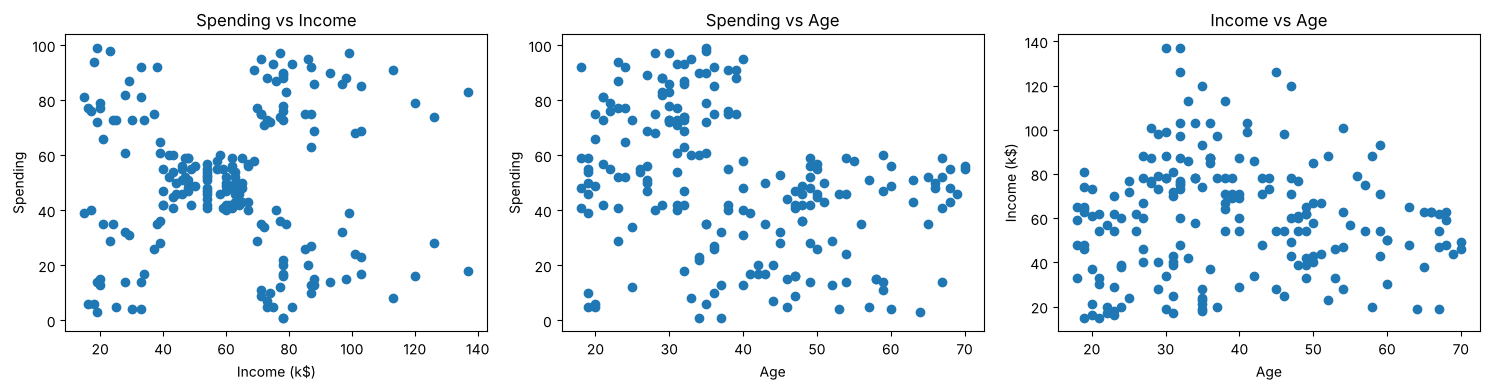

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(df["Income"], df["Spending"])
axes[0].set_xlabel("Income (k$)")
axes[0].set_ylabel("Spending")
axes[0].set_title("Spending vs Income")
axes[1].scatter(df["Age"], df["Spending"])
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Spending")
axes[1].set_title("Spending vs Age")
axes[2].scatter(df["Age"], df["Income"])
axes[2].set_xlabel("Age")
axes[2].set_ylabel("Income (k$)")
axes[2].set_title("Income vs Age")
plt.tight_layout()
plt.show()

**Interpretation:** Spending vs Income shows 5 clear blobs. The other two plots show no clear groups, so Income and Spending are the best pair for clustering.

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?

(b) Why can we not use accuracy or a train/test split to judge a clustering result?



**Your answers:**

(a) In Spending vs Income I can see 5 clear groups (low/low, low/high, middle, high/low, high/high). Spending vs Age shows no clear groups (only a loose spread), and Income vs Age also shows no clear groups. Spending vs Income shows the groups most clearly.

(b) There is no target column, so there is nothing to predict and no "correct answer" to compare with. Accuracy needs true labels, and a train/test split is only needed to test predictions. Here we only group similar points, so we judge the result with inertia, silhouette, plots and common sense.

---

## Part 1 — K-Means From Scratch (35 minutes)

In the lecture you did K-Means by hand. Here you turn your pen-and-paper steps into code, check your answers against the lecture slides, and then build your own K-Means function and compare it with scikit-learn. Using KMeans() inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: |x - m|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |
| Broadcasting | NumPy trick: x[:, None] - m[None, :] gives every point-to-centroid difference in one line. | `x[:, None, :] - C[None, :, :]` |


### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: np.abs(x[:, None] - m[None, :]) has shape (9, 2).
- Cluster of each point: dist.argmin(axis=1).


In [4]:
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)
m = np.array([4.0, 11.0])

it = 0
while True:
    it += 1
    dist = np.abs(x[:, None] - m[None, :])
    labels = dist.argmin(axis=1)
    new_m = np.array([x[labels == k].mean() if (labels == k).any() else m[k] for k in range(2)])
    print("Iteration", it)
    print("  C1:", x[labels == 0], " C2:", x[labels == 1])
    print("  New centroids:", new_m)
    if np.allclose(new_m, m):
        break
    m = new_m

inertia = sum(((x[labels == k] - m[k]) ** 2).sum() for k in range(2))
print("Final centroids:", m)
print("Inertia:", inertia)

Iteration 1
  C1: [2. 4. 3.]  C2: [10. 12. 20. 30. 11. 25.]
  New centroids: [ 3. 18.]
Iteration 2
  C1: [ 2.  4. 10.  3.]  C2: [12. 20. 30. 11. 25.]
  New centroids: [ 4.75 19.6 ]
Iteration 3
  C1: [ 2.  4. 10. 12.  3. 11.]  C2: [20. 30. 25.]
  New centroids: [ 7. 25.]
Iteration 4
  C1: [ 2.  4. 10. 12.  3. 11.]  C2: [20. 30. 25.]
  New centroids: [ 7. 25.]
Final centroids: [ 7. 25.]
Inertia: 150.0


### Task 1.2 — Lecture Example 2 in code (two features)

Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K = 2, start with P1 and P2.

1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first iteration).


In [5]:
P = np.array([[185, 72], [170, 56], [168, 60], [179, 68], [182, 72], [188, 77]], dtype=float)
M = P[[0, 1]].copy()

it = 0
while True:
    it += 1
    D = np.sqrt(((P[:, None, :] - M[None, :, :]) ** 2).sum(axis=2))
    labels = D.argmin(axis=1)
    new_M = np.array([P[labels == k].mean(axis=0) if (labels == k).any() else M[k] for k in range(2)])
    print("Iteration", it)
    for i in range(len(P)):
        print("  P%d -> cluster %d" % (i + 1, labels[i] + 1))
    print("  New centroids:", new_M.round(2).tolist())
    if it == 1:
        print("  d(P3, M2) in iteration 1 =", round(D[2, 1], 2))
    if np.allclose(new_M, M):
        break
    M = new_M

D = np.sqrt(((P[:, None, :] - M[None, :, :]) ** 2).sum(axis=2))
print("Final distance table:")
print(pd.DataFrame(D.round(2), index=["P1", "P2", "P3", "P4", "P5", "P6"], columns=["d to M1", "d to M2"]))

Iteration 1
  P1 -> cluster 1
  P2 -> cluster 2
  P3 -> cluster 2
  P4 -> cluster 1
  P5 -> cluster 1
  P6 -> cluster 1
  New centroids: [[183.5, 72.25], [169.0, 58.0]]
  d(P3, M2) in iteration 1 = 4.47
Iteration 2
  P1 -> cluster 1
  P2 -> cluster 2
  P3 -> cluster 2
  P4 -> cluster 1
  P5 -> cluster 1
  P6 -> cluster 1
  New centroids: [[183.5, 72.25], [169.0, 58.0]]
Final distance table:
    d to M1  d to M2
P1     1.52    21.26
P2    21.13     2.24
P3    19.76     2.24
P4     6.19    14.14
P5     1.52    19.10
P6     6.54    26.87


### Task 1.3 — Write your own K-Means function

Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.

1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [6]:
def my_kmeans(X, init_centroids, max_iter=100):
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    C = np.asarray(init_centroids, dtype=float).reshape(-1, X.shape[1])
    n_iter = 0
    for _ in range(max_iter):
        n_iter += 1
        d = np.sqrt(((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2))
        labels = d.argmin(axis=1)
        new_C = C.copy()
        for k in range(len(C)):
            if (labels == k).any():
                new_C[k] = X[labels == k].mean(axis=0)
            # empty cluster: keep old centroid
        if np.allclose(new_C, C):
            break
        C = new_C
    d = np.sqrt(((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2))
    labels = d.argmin(axis=1)
    inertia = (d[np.arange(len(X)), labels] ** 2).sum()
    return labels, C, inertia, n_iter

In [7]:
ex1 = [2, 4, 10, 12, 3, 20, 30, 11, 25]
lab, cen, inert, n_it = my_kmeans(ex1, [4, 11])
print("Labels:", lab)
print("Centroids:", cen.ravel())
print("Inertia:", inert)
print("Iterations:", n_it)

Labels: [0 0 0 0 0 1 1 0 1]
Centroids: [ 7. 25.]
Inertia: 150.0
Iterations: 4


### Task 1.4 — Check your function against scikit-learn

Run your function and KMeans on the same data with the same starting centroids and compare.

1. Use X2 = Income and Spending (200 x 2). Take the first 5 rows as the starting centroids.
2. Run my_kmeans. Run KMeans(n_clusters=5, init=<your 5 rows>, n_init=1, tol=0, algorithm='lloyd').
3. Compare iterations, inertia, labels and centroids.


In [8]:
X2 = df[["Income", "Spending"]].values.astype(float)
init5 = X2[:5].copy()

my_lab, my_cen, my_inert, my_it = my_kmeans(X2, init5)

km = KMeans(n_clusters=5, init=init5, n_init=1, tol=0, algorithm="lloyd").fit(X2)

print("Iterations  -> mine:", my_it, "| sklearn:", km.n_iter_)
print("Inertia     -> mine:", round(my_inert, 4), "| sklearn:", round(km.inertia_, 4))
print("Labels equal:", np.array_equal(my_lab, km.labels_))
print("Centroids equal:", np.allclose(my_cen, km.cluster_centers_))
print("My centroids:")
print(my_cen.round(3))
print("Sklearn centroids:")
print(km.cluster_centers_.round(3))

Iterations  -> mine: 4 | sklearn: 4
Inertia     -> mine: 44448.4554 | sklearn: 44448.4554
Labels equal: True
Centroids equal: True
My centroids:
[[26.304 20.913]
 [25.727 79.364]
 [88.2   17.114]
 [86.538 82.128]
 [55.296 49.519]]
Sklearn centroids:
[[26.304 20.913]
 [25.727 79.364]
 [88.2   17.114]
 [86.538 82.128]
 [55.296 49.519]]


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?



**Your answers:**

(a) Start centroids were 4 and 11. Point 10 is 1 away from 11 and 6 away from 4, so it went to C2. After iteration 1 the centroids became 3 and 18. Now point 10 is 7 away from 3 and 8 away from 18, so it moved to C1.

(b) The loop stops when the centroids stop moving (no point changes cluster). In Example 1 this happened at iteration 4 (centroids 7 and 25). It always stops because each step lowers or keeps the inertia and there are only a finite number of ways to group the points. But it can stop in a local minimum, so the result is not always the best one.

(c) Yes, it matched exactly. Iterations: 4 and 4. Inertia: 44448.4554 for both. Labels are equal and centroids are equal.

(d) A centroid is the average customer of a group, for example Income 26.3 and Spending 20.9 for one cluster. Features must be numeric because K-Means uses means and distances, which cannot be calculated on text.

---

## Part 2 — Choosing K: Elbow and Silhouette (30 minutes)

The algorithm needs K before it starts, but nobody tells us K. The lecture gave two tools: the elbow (inertia) and the silhouette score. Here you use both, then calculate a silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |


### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit KMeans(n_clusters=K, n_init=10, random_state=SEED) and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.


 K     Inertia  Silhouette
 2 181363.5960      0.2969
 3 106348.3731      0.4676
 4  73679.7890      0.4932
 5  44448.4554      0.5539
 6  37233.8145      0.5398
 7  30241.3436      0.5288
 8  25036.4176      0.4548
 9  21916.7948      0.4561
10  20072.0709      0.4411


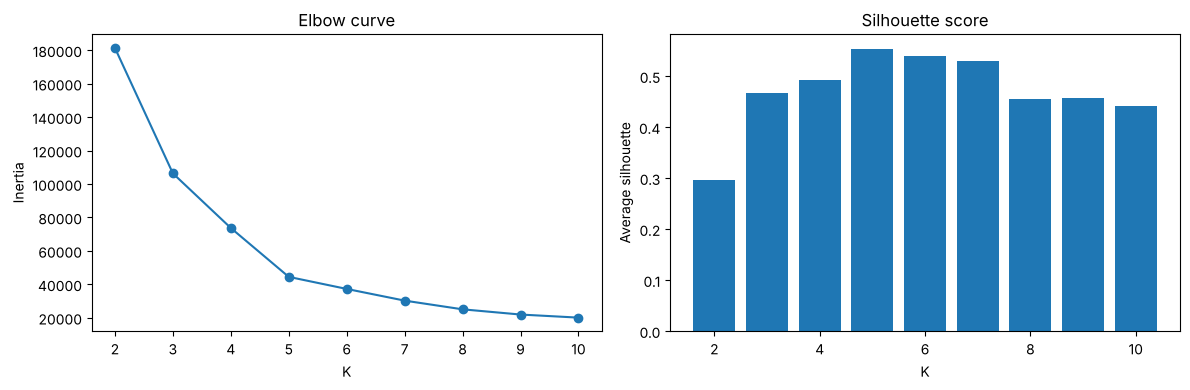

K with highest silhouette: 5
Inertia drop K=4 to 5: 29231.3
Inertia drop K=5 to 6: 7214.6


In [9]:
rows = []
for k in range(2, 11):
    m_k = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X2)
    rows.append([k, m_k.inertia_, silhouette_score(X2, m_k.labels_)])
res = pd.DataFrame(rows, columns=["K", "Inertia", "Silhouette"])
print(res.round(4).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(res["K"], res["Inertia"], marker="o")
ax[0].set_xlabel("K")
ax[0].set_ylabel("Inertia")
ax[0].set_title("Elbow curve")
ax[1].bar(res["K"], res["Silhouette"])
ax[1].set_xlabel("K")
ax[1].set_ylabel("Average silhouette")
ax[1].set_title("Silhouette score")
plt.tight_layout()
plt.show()

best_k = int(res.loc[res["Silhouette"].idxmax(), "K"])
print("K with highest silhouette:", best_k)
print("Inertia drop K=4 to 5:", round(res.loc[res.K == 4, "Inertia"].values[0] - res.loc[res.K == 5, "Inertia"].values[0], 1))
print("Inertia drop K=5 to 6:", round(res.loc[res.K == 5, "Inertia"].values[0] - res.loc[res.K == 6, "Inertia"].values[0], 1))

**Interpretation:** The inertia curve bends at K=5 and the silhouette is highest at K=5 (0.5539), so K=5 is the best choice.

### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point (use only NumPy distances). Apply it to customer 1 (row 0) and compare with silhouette_samples.
2. Show the count, mean and minimum silhouette of every cluster, and the number of customers with a negative silhouette.
3. Draw a silhouette plot of all customers sorted inside each cluster.


In [10]:
km5 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
lab5 = km5.labels_

def silhouette_one(X, labels, i):
    d = np.sqrt(((X - X[i]) ** 2).sum(axis=1))
    own = labels[i]
    same = (labels == own)
    same[i] = False
    a = d[same].mean()
    b = min(d[labels == c].mean() for c in np.unique(labels) if c != own)
    s = (b - a) / max(a, b)
    return a, b, s

a0, b0, s0 = silhouette_one(X2, lab5, 0)
sil_all = silhouette_samples(X2, lab5)
print("Customer 1 -> a = %.4f, b = %.4f, s = %.4f" % (a0, b0, s0))
print("silhouette_samples for customer 1:", round(sil_all[0], 4))

Customer 1 -> a = 24.6404, b = 42.2653, s = 0.4170
silhouette_samples for customer 1: 0.417


         Count    Mean     Min
Cluster                       
0           81  0.5967  0.1153
1           39  0.5092  0.2254
2           22  0.5990  0.0507
3           35  0.5040 -0.0234
4           23  0.5123 -0.0093
Customers with negative silhouette: 2


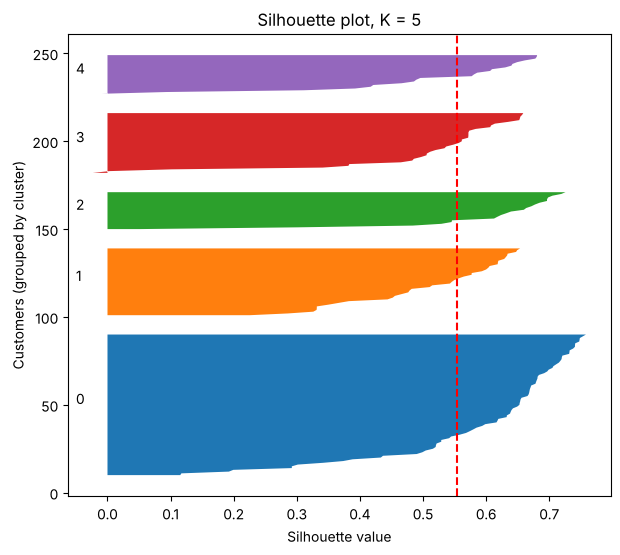

In [11]:
sil_df = pd.DataFrame({"Cluster": lab5, "Silhouette": sil_all})
stats = sil_df.groupby("Cluster")["Silhouette"].agg(Count="count", Mean="mean", Min="min")
print(stats.round(4))
print("Customers with negative silhouette:", int((sil_all < 0).sum()))

fig, ax = plt.subplots(figsize=(7, 6))
y_low = 10
for c in range(5):
    vals = np.sort(sil_all[lab5 == c])
    ax.fill_betweenx(np.arange(y_low, y_low + len(vals)), 0, vals)
    ax.text(-0.05, y_low + len(vals) / 2, str(c))
    y_low += len(vals) + 10
ax.axvline(sil_all.mean(), color="red", linestyle="--")
ax.set_xlabel("Silhouette value")
ax.set_ylabel("Customers (grouped by cluster)")
ax.set_title("Silhouette plot, K = 5")
plt.show()

**Interpretation:** All 5 clusters have a mean silhouette of about 0.50 to 0.60. Only 2 customers are negative, so the clusters are well formed.

### Task 2.3 — The lecture practice problem

Points 1, 3, 5, 7, 11, 13, 15 with K = 2 and starting centroids 1 and 11 (the 'Practice' slide).

1. Run your my_kmeans on these points and print the final clusters, centroids and iterations.
2. Calculate a, b and s for the points 1, 7 and 11 with your function and compare with silhouette_samples.
3. Also write the iterations on paper (clusters and centroids after each iteration) and keep the photo or notes for your own revision.


In [12]:
pts = np.array([1, 3, 5, 7, 11, 13, 15], dtype=float)
lab_p, cen_p, inert_p, it_p = my_kmeans(pts, [1, 11])
print("Cluster 0:", pts[lab_p == 0])
print("Cluster 1:", pts[lab_p == 1])
print("Centroids:", cen_p.ravel())
print("Inertia:", inert_p, "| Iterations:", it_p)

Xp = pts.reshape(-1, 1)
sil_p = silhouette_samples(Xp, lab_p)
for p in [1, 7, 11]:
    i = int(np.where(pts == p)[0][0])
    a, b, s = silhouette_one(Xp, lab_p, i)
    print("Point %2d -> a = %.3f, b = %.3f, s = %.3f | sklearn s = %.3f" % (p, a, b, s, sil_p[i]))

Cluster 0: [1. 3. 5. 7.]
Cluster 1: [11. 13. 15.]
Centroids: [ 4. 13.]
Inertia: 28.0 | Iterations: 3
Point  1 -> a = 4.000, b = 12.000, s = 0.667 | sklearn s = 0.667
Point  7 -> a = 4.000, b = 6.000, s = 0.333 | sklearn s = 0.333
Point 11 -> a = 3.000, b = 7.000, s = 0.571 | sklearn s = 0.571


**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).

(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.

(d) Why should we never choose K only by the lowest inertia?



**Your answers:**

(a) The elbow bends at K=5: inertia drops by 29231.3 from K=4 to 5, but only by 7214.6 from K=5 to 6. The silhouette is highest at K=5 (0.5539). So both methods agree on K=5.

(b) Customer 1 has silhouette 0.417 (a = 24.64, b = 42.27). This means it is placed reasonably well but not very strongly. Cluster 3 has the weakest average silhouette (0.504). 2 customers have a negative silhouette (one in cluster 3 and one in cluster 4).

(c) Point 7 is less well placed. Point 1 has a = 4 and b = 12 (s = 0.667), so it is clearly inside its cluster. Point 7 has a = 4 but b = 6 (s = 0.333), so it is much closer to the other cluster.

(d) Inertia always goes down when K grows (with K = number of points it would be 0). So the lowest inertia would always choose a too large K and give useless clusters. We must also check the elbow and the silhouette.

---

## Part 3 — Starting Points and Stability (20 minutes)

The lecture said 'starting points matter - run several starts and keep the best'. You will now measure how much, using the same data and the same K.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |


### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in three settings: init='random' with n_init=1, k-means++ with n_init=1, k-means++ with n_init=10.
2. Build a table: setting, number of distinct final inertia values (round to 1 decimal), lowest, highest, and the percentage of runs that reached the best inertia.
3. Draw one histogram of the final inertia values for the three settings.


             Setting  Distinct inertia   Lowest  Highest  % runs at best
    random, n_init=1                14 44448.46 91761.98            33.3
 k-means++, n_init=1                 6 44448.46 66733.44            60.0
k-means++, n_init=10                 1 44448.46 44448.46           100.0


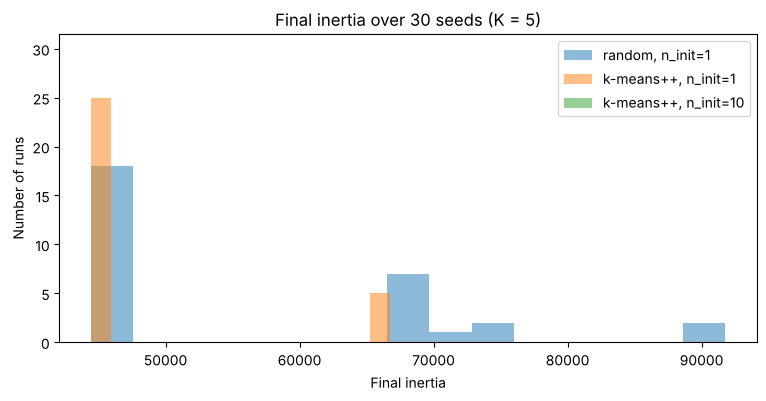

In [13]:
settings = {
    "random, n_init=1": dict(init="random", n_init=1),
    "k-means++, n_init=1": dict(init="k-means++", n_init=1),
    "k-means++, n_init=10": dict(init="k-means++", n_init=10),
}
runs = {}
for name, kw in settings.items():
    runs[name] = [KMeans(n_clusters=5, random_state=s, **kw).fit(X2) for s in range(30)]

global_best = min(m_.inertia_ for r in runs.values() for m_ in r)
table = []
for name, r in runs.items():
    inert_vals = np.array([m_.inertia_ for m_ in r])
    table.append([
        name,
        len(np.unique(inert_vals.round(1))),
        inert_vals.min().round(2),
        inert_vals.max().round(2),
        round(100 * np.mean(np.isclose(inert_vals, global_best, atol=0.1)), 1),
    ])
tab = pd.DataFrame(table, columns=["Setting", "Distinct inertia", "Lowest", "Highest", "% runs at best"])
print(tab.to_string(index=False))

plt.figure(figsize=(9, 4))
for name, r in runs.items():
    plt.hist([m_.inertia_ for m_ in r], bins=15, alpha=0.5, label=name)
plt.xlabel("Final inertia")
plt.ylabel("Number of runs")
plt.title("Final inertia over 30 seeds (K = 5)")
plt.legend()
plt.show()

**Interpretation:** Random start often ends in worse solutions (only 33.3% best). k-means++ is better (60.0%) and n_init=10 reached the best result in 100% of the runs.

### Task 3.2 — Best run vs worst run

See what a bad local minimum looks like.

1. From the random-init runs take the best and the worst. Draw both clusterings with their centroids side by side.
2. Print their inertia and their ARI.


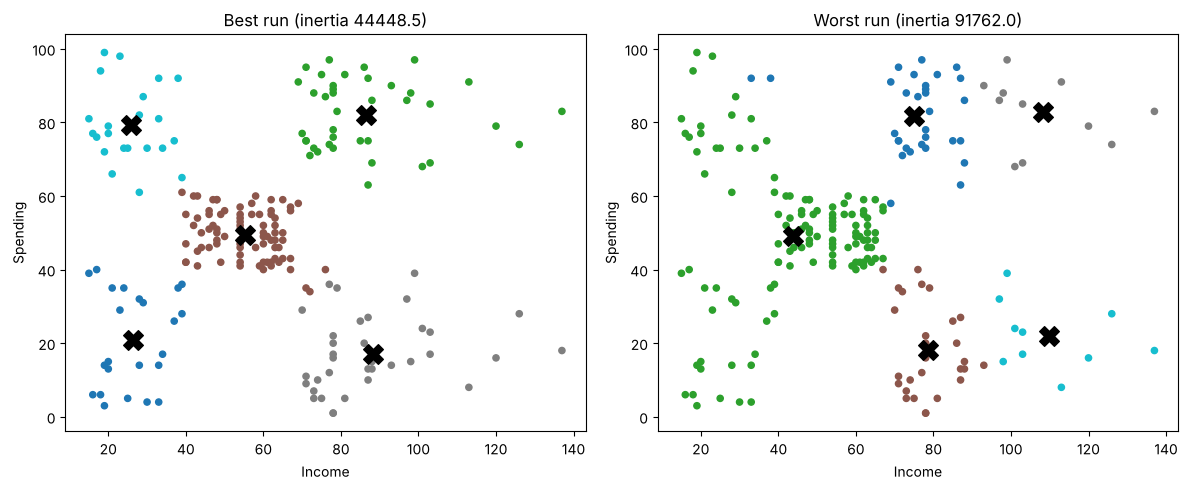

Best inertia : 44448.46
Worst inertia: 91761.98
ARI between best and worst: 0.4553


In [14]:
rand_runs = runs["random, n_init=1"]
best_m = min(rand_runs, key=lambda m_: m_.inertia_)
worst_m = max(rand_runs, key=lambda m_: m_.inertia_)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a_, m_, t in zip(ax, [best_m, worst_m], ["Best run", "Worst run"]):
    a_.scatter(X2[:, 0], X2[:, 1], c=m_.labels_, cmap="tab10", s=20)
    a_.scatter(m_.cluster_centers_[:, 0], m_.cluster_centers_[:, 1], c="black", marker="X", s=200)
    a_.set_xlabel("Income")
    a_.set_ylabel("Spending")
    a_.set_title("%s (inertia %.1f)" % (t, m_.inertia_))
plt.tight_layout()
plt.show()

print("Best inertia :", round(best_m.inertia_, 2))
print("Worst inertia:", round(worst_m.inertia_, 2))
print("ARI between best and worst:", round(adjusted_rand_score(best_m.labels_, worst_m.labels_), 4))

**Interpretation:** The worst run (inertia 91761.98) splits the data badly, while the best run (44448.46) shows the 5 natural groups. ARI 0.4553 shows they are different groupings.

**Questions** (answer with your own numbers)

(a) How many different final inertia values did the random-start setting produce, and what percentage of its runs reached the best one? Compare with the other two settings.

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init help? What did n_init=10 give in your table?

(d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly?



**Your answers:**

(a) Random start (n_init=1) gave 14 different inertia values, and only 33.3% of the runs reached the best inertia (44448.46). k-means++ (n_init=1) gave 6 different values and 60.0% reached the best. k-means++ with n_init=10 gave 1 value and 100% reached the best.

(b) The starting centroids are different, so the loop can end in a different local minimum. The worst random run had inertia 91761.98 compared with the best 44448.46.

(c) k-means++ chooses starting centroids far from each other, so bad starts happen less. n_init runs several starts and keeps the one with the lowest inertia. With n_init=10 all 30 seeds gave the same best inertia (44448.46).

(d) Cluster numbers are just names and can change between runs (cluster 2 in one run can be cluster 4 in another). ARI compares the actual grouping of the points, so it ignores the numbers. The best and worst run had ARI 0.4553, so they are quite different.

---

## Part 4 — Scaling: Units Decide the Clusters (25 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it twice: once by only changing the unit of Income, and once on the Wine data where the features have very different sizes and the true groups are known.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| External check | Comparing clusters with known true groups. Possible only for teaching data like Wine. Real clustering problems have no labels. | `adjusted_rand_score(y_true, labels)` |
| PCA (Lab 8) | Reduces many features to 2 so we can draw the data. Used here only for the plot. | `PCA(n_components=2)` |


### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, n_init=10, random_state=SEED).
2. Print ARI between: raw k$ vs raw dollars, scaled k$ vs scaled dollars, raw dollars vs scaled dollars.
3. Draw Age vs Income (in k$) coloured by the clusters of raw k$, raw dollars and scaled.


ARI raw k$ vs raw dollars      : 0.4897
ARI scaled k$ vs scaled dollars: 1.0
ARI raw dollars vs scaled      : 0.3605


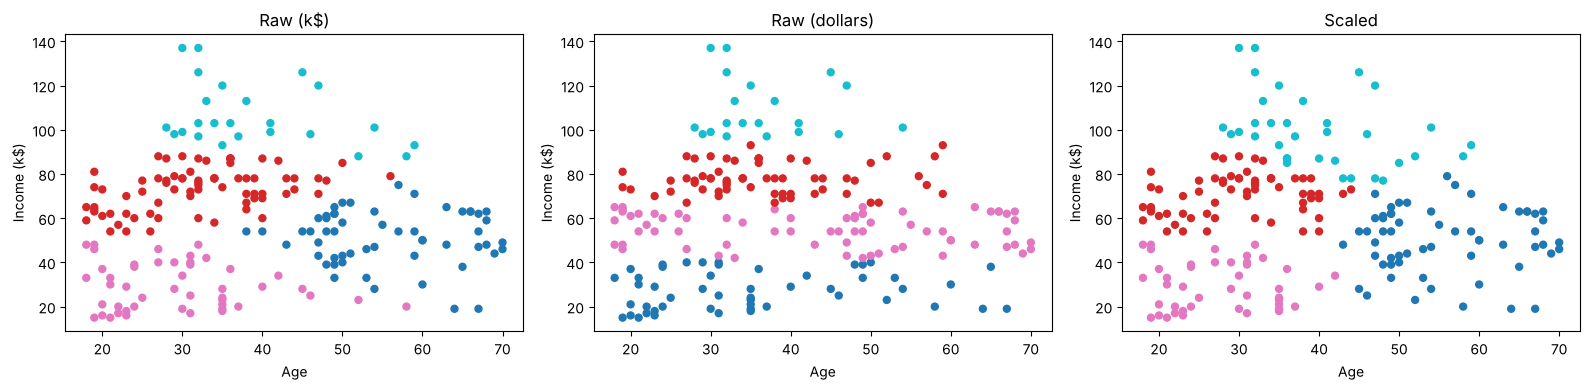

In [15]:
AI_k = df[["Age", "Income"]].values.astype(float)
AI_d = AI_k.copy()
AI_d[:, 1] = AI_d[:, 1] * 1000

def fit4(X):
    return KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X).labels_

lab_raw_k = fit4(AI_k)
lab_raw_d = fit4(AI_d)
lab_sc_k = fit4(StandardScaler().fit_transform(AI_k))
lab_sc_d = fit4(StandardScaler().fit_transform(AI_d))

print("ARI raw k$ vs raw dollars      :", round(adjusted_rand_score(lab_raw_k, lab_raw_d), 4))
print("ARI scaled k$ vs scaled dollars:", round(adjusted_rand_score(lab_sc_k, lab_sc_d), 4))
print("ARI raw dollars vs scaled      :", round(adjusted_rand_score(lab_raw_d, lab_sc_d), 4))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a_, lab_, t in zip(ax, [lab_raw_k, lab_raw_d, lab_sc_k], ["Raw (k$)", "Raw (dollars)", "Scaled"]):
    a_.scatter(df["Age"], df["Income"], c=lab_, cmap="tab10", s=25)
    a_.set_xlabel("Age")
    a_.set_ylabel("Income (k$)")
    a_.set_title(t)
plt.tight_layout()
plt.show()

**Interpretation:** Changing only the unit of Income changes the raw clusters (ARI 0.4897). After scaling, both units give the same clusters (ARI 1.0).

### Task 4.2 — Wine data: raw vs scaled

Load the Wine data with load_wine(): 178 wines, 13 chemical measurements, 3 true grape cultivars. The true cultivar is used ONLY to check the result, never to fit K-Means.

1. Print the three largest and the smallest standard deviation of the features.
2. Run KMeans(K=3, n_init=10, random_state=SEED) on the raw data and on the scaled data. For each report ARI against the true cultivar, silhouette score and cluster sizes.


In [16]:
wine = load_wine()
Xw = wine.data
yw = wine.target
stds = pd.Series(Xw.std(axis=0), index=wine.feature_names).sort_values(ascending=False)
print("Three largest std:")
print(stds.head(3).round(3))
print("Smallest std:")
print(stds.tail(1).round(4))

Three largest std:
proline              314.022
magnesium             14.242
alcalinity_of_ash      3.330
dtype: float64
Smallest std:
nonflavanoid_phenols    0.1241
dtype: float64


In [17]:
Xw_sc = StandardScaler().fit_transform(Xw)

km_raw = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Xw)
km_sc = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Xw_sc)

for name, model, Xuse in [("Raw", km_raw, Xw), ("Scaled", km_sc, Xw_sc)]:
    print(name)
    print("  ARI vs true cultivar:", round(adjusted_rand_score(yw, model.labels_), 4))
    print("  Silhouette          :", round(silhouette_score(Xuse, model.labels_), 4))
    print("  Cluster sizes       :", np.bincount(model.labels_).tolist())

Raw
  ARI vs true cultivar: 0.3711
  Silhouette          : 0.5711
  Cluster sizes       : [62, 47, 69]
Scaled
  ARI vs true cultivar: 0.8975
  Silhouette          : 0.2849
  Cluster sizes       : [65, 51, 62]


**Interpretation:** Scaling improves the match with the true cultivars a lot (ARI 0.3711 to 0.8975), even though the silhouette is lower (0.2849).

### Task 4.3 — Draw it

Compare the three views in one picture.

1. Use one PCA of the scaled data and draw three plots with the same axes: true cultivars, raw clusters, scaled clusters.


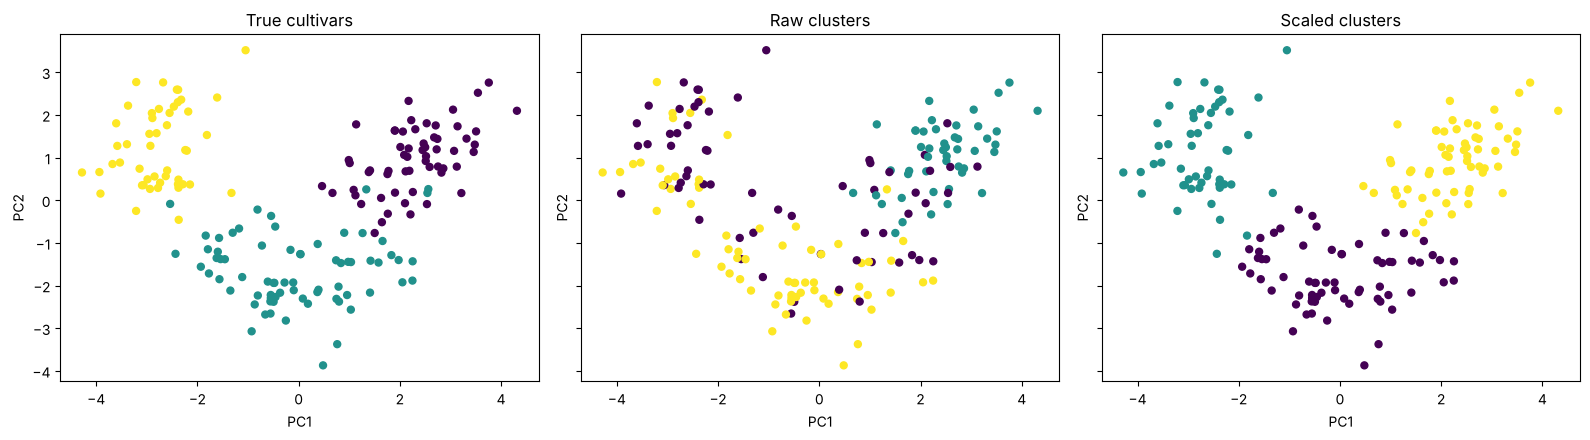

In [18]:
pca = PCA(n_components=2)
Z = pca.fit_transform(Xw_sc)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)
for a_, lab_, t in zip(ax, [yw, km_raw.labels_, km_sc.labels_],
                       ["True cultivars", "Raw clusters", "Scaled clusters"]):
    a_.scatter(Z[:, 0], Z[:, 1], c=lab_, cmap="viridis", s=25)
    a_.set_xlabel("PC1")
    a_.set_ylabel("PC2")
    a_.set_title(t)
plt.tight_layout()
plt.show()

**Interpretation:** The scaled clusters look much like the true cultivars. The raw clusters cut the data in a different way because proline dominates.

**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula (which feature controls the distance now?).

(b) On the Wine data which feature dominated the raw distance and how big is its standard deviation compared with the others? What were the ARI values raw vs scaled?

(c) The silhouette was higher on the raw Wine data although the clustering was worse. Explain why a silhouette can mislead here and why comparing it between raw and scaled data is not fair.

(d) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.



**Your answers:**

(a) The clusters changed (ARI raw k$ vs raw dollars = 0.4897). In dollars Income goes from 15000 to 137000 while Age is only 18 to 70. In the distance formula the Income difference is now thousands of times bigger than the Age difference, so Income alone controls the distance. After scaling the result is the same in both units (ARI = 1.0).

(b) Proline dominated the raw distance. Its standard deviation is 314.02, compared with 14.24 for magnesium (second largest), 3.33 for alcalinity of ash and 0.124 for the smallest (nonflavanoid phenols). ARI against the true cultivar was 0.3711 for raw and 0.8975 for scaled.

(c) The raw silhouette was 0.5711 and the scaled one was 0.2849, even though raw clustering was worse. On raw data one feature (proline) makes the groups look well separated, so the silhouette is high, but it only measures distance in that dominated space. Silhouettes of raw and scaled data are calculated in different spaces with different distances, so they cannot be compared fairly.

(d) My rule: scale when the features have different units or very different standard deviations (check df.std()). Then compare the clusters and plots to see if they make sense, and by default scale.

---

## Part 5 — Outliers and Anomalies (20 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and then catch it with a distance rule (the anomaly detection idea from the lecture).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |
| Anomaly detection | Using the clusters to find strange points (far from every centroid). | `Sort by the distance column.` |


### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (n_init=10, random_state=SEED) without and with the extra customer.
2. Print the cluster sizes, the centroids (sorted by income) and the ARI between the two results on the original 200 customers.
3. Draw the two clusterings side by side.


In [19]:
X_out = np.vstack([X2, [400, 99]])

km_a = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
km_b = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X_out)

def sorted_centroids(model):
    c = model.cluster_centers_
    return c[np.argsort(c[:, 0])].round(2)

print("Without extra: sizes =", np.bincount(km_a.labels_).tolist())
print(sorted_centroids(km_a))
print("With extra   : sizes =", np.bincount(km_b.labels_).tolist())
print(sorted_centroids(km_b))
print("ARI on the original 200 customers:", round(adjusted_rand_score(km_a.labels_, km_b.labels_[:200]), 4))

Without extra: sizes = [81, 39, 22, 35, 23]
[[25.73 79.36]
 [26.3  20.91]
 [55.3  49.52]
 [86.54 82.13]
 [88.2  17.11]]
With extra   : sizes = [100, 1, 23, 39, 38]
[[ 26.3   20.91]
 [ 48.26  56.48]
 [ 86.54  82.13]
 [ 87.    18.63]
 [400.    99.  ]]
ARI on the original 200 customers: 0.7532


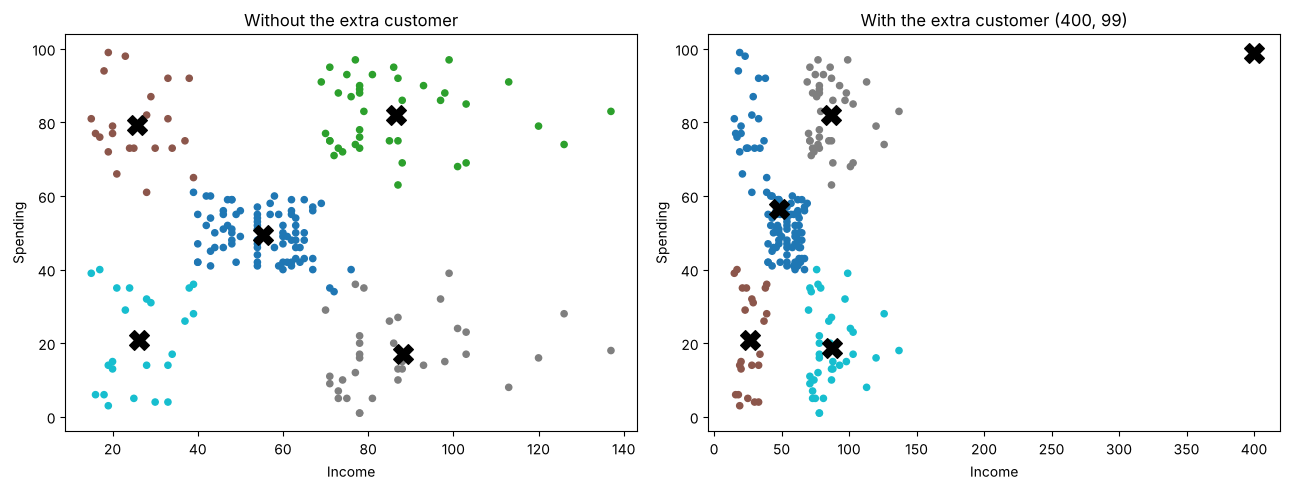

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(X2[:, 0], X2[:, 1], c=km_a.labels_, cmap="tab10", s=20)
ax[0].scatter(km_a.cluster_centers_[:, 0], km_a.cluster_centers_[:, 1], c="black", marker="X", s=200)
ax[0].set_title("Without the extra customer")
ax[1].scatter(X_out[:, 0], X_out[:, 1], c=km_b.labels_, cmap="tab10", s=20)
ax[1].scatter(km_b.cluster_centers_[:, 0], km_b.cluster_centers_[:, 1], c="black", marker="X", s=200)
ax[1].set_title("With the extra customer (400, 99)")
for a_ in ax:
    a_.set_xlabel("Income")
    a_.set_ylabel("Spending")
plt.tight_layout()
plt.show()

**Interpretation:** With the extra customer, one cluster is used only for that one point and the real groups are merged, so the result is worse.

### Task 5.2 — Catch it and repair

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). How many real customers are flagged? Is the extra customer flagged?
3. Show the 5 real customers that are farthest from their centroid (CustomerID, Age, Income, Spending, Cluster, Distance).
4. Remove all flagged points, refit K = 5 and report the cluster sizes and the ARI against the original model on the 200 customers (use predict).


In [21]:
dist_real = km_a.transform(X2).min(axis=1)
dist_extra = km_a.transform(np.array([[400, 99]])).min(axis=1)[0]

threshold = dist_real.mean() + 3 * dist_real.std()
flag_real = dist_real > threshold
print("Threshold (mean + 3 std):", round(threshold, 2))
print("Extra customer distance :", round(dist_extra, 2), "| flagged:", bool(dist_extra > threshold))
print("Real customers flagged  :", int(flag_real.sum()))

top = df.copy()
top["Cluster"] = km_a.labels_
top["Distance"] = dist_real
print(top.sort_values("Distance", ascending=False).head(5)[["CustomerID", "Age", "Income", "Spending", "Cluster", "Distance"]].round(2).to_string(index=False))

# remove flagged points (real flagged + extra if flagged) and refit
dist_all = km_a.transform(X_out).min(axis=1)
keep = dist_all <= threshold
km_c = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X_out[keep])
print("Points removed:", int((~keep).sum()))
print("Cluster sizes after repair:", np.bincount(km_c.labels_).tolist())
print("ARI vs original model on 200 customers:", round(adjusted_rand_score(km_a.labels_, km_c.predict(X2)), 4))

Threshold (mean + 3 std): 34.8
Extra customer distance : 313.92 | flagged: True
Real customers flagged  : 4
 CustomerID  Age  Income  Spending  Cluster  Distance
        200   30     137        83        1     50.47
        199   32     137        18        3     48.81
        198   32     126        74        1     40.29
        197   45     126        28        3     39.34
        196   35     120        79        1     33.61
Points removed: 5
Cluster sizes after repair: [80, 34, 23, 37, 22]
ARI vs original model on 200 customers: 0.9847


**Interpretation:** The extra customer is flagged clearly (distance 313.92 vs threshold 34.80). 4 real high-income customers are also flagged. After repair the clusters are almost the same as the original (ARI 0.9847).

**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and centroids.

(b) How well did the rule detect the extra customer? The rule also flagged some real customers: are they mistakes in the data or something worth looking at? Look at their Income and Spending.

(c) Name two ways to deal with outliers and one risk of simply deleting them.



**Your answers:**

(a) The extra customer (400, 99) took one cluster for itself (size 1). The other 200 customers had to share 4 clusters, so sizes changed from [81, 39, 22, 35, 23] to [100, 1, 23, 39, 38]. The low income / high spending group (22) was merged into the middle group: that cluster centroid moved from (55.3, 49.5) to (48.3, 56.5). ARI on the original 200 customers was only 0.7532.

(b) The rule found it clearly: its distance is 313.92 and the threshold is 34.80. It also flagged 4 real customers (CustomerID 197 to 200). They have very high incomes (126 to 137), so they are not mistakes. They are real rich customers at the edge of the data and worth looking at.

(c) Two ways: (1) cap/transform the extreme values, or (2) use a method that is not sensitive to outliers (for example K-Medoids or DBSCAN), or study them separately. Risk of deleting: we may remove real and important customers, such as VIP customers. After removing the 5 flagged points, the ARI with the original model was 0.9847.

---

## Part 6 — From Clusters to Customer Segments (25 minutes)

Clusters are numbers (0, 1, 2 ...). The business needs names and actions. Cluster numbers are arbitrary labels: cluster 3 in one run has no meaning by itself. Use the original 200 customers and K = 5 on Income and Spending (random_state=SEED).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Cluster profile | The average of every feature inside each cluster, plus the cluster size. This is how you read what a cluster means. | `df.groupby('Cluster').agg(...)` |
| Segment | A cluster with a name and an action, for example 'High income / Low spending'. | `df['Cluster'].map(names)` |
| Crosstab | Counts or percentages of one category inside another (Gender inside Segment). | `pd.crosstab(a, b, normalize='index')` |


### Task 6.1 — Profile and name the segments

Make the clustering readable for a manager.

1. Add the cluster number to the data. Build a profile table: number of customers, mean Age, mean Income, mean Spending and % female for each cluster, sorted by Income.
2. Create segment names with a small rule (Income below 40 = Low, 70 or more = High, otherwise Mid; Spending below 35 = Low, 65 or more = High, otherwise Mid). Print the size of each segment.


In [22]:
df["Cluster"] = km_a.labels_
df["IsFemale"] = (df["Gender"] == "Female").astype(int)
profile = df.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Age=("Age", "mean"),
    Income=("Income", "mean"),
    Spending=("Spending", "mean"),
    PctFemale=("IsFemale", lambda s: 100 * s.mean()),
).sort_values("Income")
print(profile.round(1))

         Customers   Age  Income  Spending  PctFemale
Cluster                                              
2               22  25.3    25.7      79.4       59.1
4               23  45.2    26.3      20.9       60.9
0               81  42.7    55.3      49.5       59.3
1               39  32.7    86.5      82.1       53.8
3               35  41.1    88.2      17.1       45.7


In [23]:
def seg_name(row):
    inc = "Low" if row["Income"] < 40 else ("High" if row["Income"] >= 70 else "Mid")
    spd = "Low" if row["Spending"] < 35 else ("High" if row["Spending"] >= 65 else "Mid")
    return inc + " income / " + spd + " spending"

cluster_to_segment = {c: seg_name(r) for c, r in profile.iterrows()}
df["Segment"] = df["Cluster"].map(cluster_to_segment)
print(df["Segment"].value_counts())

Segment
Mid income / Mid spending      81
High income / High spending    39
High income / Low spending     35
Low income / Low spending      23
Low income / High spending     22
Name: count, dtype: int64


**Interpretation:** The profile table and segment names show 5 clear customer types. The biggest segment is Mid income / Mid spending (81 customers).

### Task 6.2 — Does Gender matter? Does Age matter?

Gender and Age were not used in the clusters. Check whether they would add something.

1. Show the % of women in each segment and the overall %.
2. Scale Age, Income and Spending together and print the average silhouette for K = 2 to 8.


In [24]:
print("% women in each segment:")
print((pd.crosstab(df["Segment"], df["Gender"], normalize="index") * 100).round(1))
print("Overall % women:", round(100 * df["IsFemale"].mean(), 1))

X3 = StandardScaler().fit_transform(df[["Age", "Income", "Spending"]].values.astype(float))
sil3 = []
for k in range(2, 9):
    l = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X3)
    sil3.append([k, silhouette_score(X3, l)])
sil3 = pd.DataFrame(sil3, columns=["K", "Silhouette"])
print(sil3.round(4).to_string(index=False))

% women in each segment:
Gender                       Female  Male
Segment                                  
High income / High spending    53.8  46.2
High income / Low spending     45.7  54.3
Low income / High spending     59.1  40.9
Low income / Low spending      60.9  39.1
Mid income / Mid spending      59.3  40.7
Overall % women: 56.0
 K  Silhouette
 2      0.3355
 3      0.3578
 4      0.4040
 5      0.4166
 6      0.4284
 7      0.4172
 8      0.4082


**Interpretation:** Women are 56.0% overall and between 45.7% and 60.9% in each segment, so gender adds little. With 3 features the silhouette is highest at K=6 (0.4284).

### Task 6.3 — A three-feature alternative

Cluster the scaled Age, Income and Spending with the best K from the table above.

1. Fit it, build its profile table (size, Age, Income, Spending) sorted by Age.
2. Print the ARI between this segmentation and your 2-feature K = 5 segmentation.


In [25]:
best_k3 = int(sil3.loc[sil3["Silhouette"].idxmax(), "K"])
print("Best K for 3 features:", best_k3)
km3 = KMeans(n_clusters=best_k3, n_init=10, random_state=SEED).fit(X3)
df["Cluster3"] = km3.labels_
profile3 = df.groupby("Cluster3").agg(
    Customers=("CustomerID", "count"),
    Age=("Age", "mean"),
    Income=("Income", "mean"),
    Spending=("Spending", "mean"),
).sort_values("Age")
print(profile3.round(1))
print("ARI (3-feature vs 2-feature K=5):", round(adjusted_rand_score(df["Cluster"], df["Cluster3"]), 4))

Best K for 3 features: 6
          Customers   Age  Income  Spending
Cluster3                                   
4                23  25.0    25.3      77.6
1                39  26.8    57.1      48.1
3                39  32.7    86.5      82.1
2                33  41.9    88.9      17.0
5                21  45.5    26.3      19.4
0                45  56.3    54.3      49.1
ARI (3-feature vs 2-feature K=5): 0.7002


**Interpretation:** Adding Age gives 6 groups. It mainly splits the middle group by age. ARI 0.7002 shows it is similar but not the same as the 2-feature segmentation.

**Questions** (answer with your own numbers)

(a) Give each of the 5 segments a short business name and one concrete action (an offer or a message). Use the numbers from your profile table.

(b) Which segment is the most valuable now and which one is the biggest opportunity? Why?

(c) Does Gender help to separate the segments? Quote the percentages.

(d) Does adding Age change the story? Which segmentation would you present and why? (Careful: silhouette values from different feature sets are not directly comparable.)



**Your answers:**

(a) Segments and actions:
- Cluster 0 (81 customers, income 55.3, spending 49.5): "Average shoppers". Action: loyalty points to increase visits.
- Cluster 1 (39 customers, income 86.5, spending 82.1): "VIP big spenders". Action: early access to new products and premium offers.
- Cluster 3 (35 customers, income 88.2, spending 17.1): "Careful rich". Action: personal offers and premium quality products to increase their spending.
- Cluster 2 (22 customers, age 25.3, income 25.7, spending 79.4): "Young trend lovers". Action: student/young discounts and installment offers.
- Cluster 4 (23 customers, income 26.3, spending 20.9): "Budget savers". Action: low-price deals and coupons.

(b) The most valuable now is the VIP big spenders (high income and high spending, 39 customers). The biggest opportunity is the careful rich (35 customers): they have the same high income (88.2) but spend very little (17.1), so even a small increase gives large revenue.

(c) Gender does not help much. Overall 56.0% are women, and the segments range only from 45.7% to 60.9% (for example 53.8% in high/high and 60.9% in low/low).

(d) Age adds a little. The 3-feature model chose K=6 (silhouette 0.4284) and the ARI with the 2-feature model is 0.7002. It mostly splits the middle group into young (age 26.8) and older (age 56.3) customers. I would present the 2-feature K=5 segmentation because it is simpler, has a clear elbow and best silhouette (0.5539), and gives clear business actions. Age can be used as an extra insight.

---

## Part 7 — Final Output and Wrap-Up (15 minutes)

Package your result like you would give it to a marketing team.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |


### Task 7.1 — Save the segments

Create a CSV with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.

1. Save it as customer_segments.csv and print the number of customers per segment.
2. Write a 6-8 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, one action per segment (short), how you handled scaling and outliers, and one limitation.


In [26]:
out = df[["CustomerID", "Age", "Gender", "Income", "Spending", "Cluster", "Segment"]]
out.to_csv("customer_segments.csv", index=False)
print(out["Segment"].value_counts())
print("Saved customer_segments.csv with", len(out), "rows")

Segment
Mid income / Mid spending      81
High income / High spending    39
High income / Low spending     35
Low income / Low spending      23
Low income / High spending     22
Name: count, dtype: int64
Saved customer_segments.csv with 200 rows


**Executive Summary** (6-8 lines)

1. I chose K = 5 on Income and Spending. The elbow bends at K=5 (inertia drop 29231 from K=4 to 5, only 7215 from 5 to 6) and the silhouette is highest at K=5 (0.5539).
2. Segments (size): Mid income / Mid spending (81), High / High (39), High income / Low spending (35), Low income / Low spending (23), Low income / High spending (22).
3. Actions: loyalty points for the middle group; VIP early access for high/high; personal premium offers for high income / low spending; low-price coupons for low/low; student discounts and installments for low income / high spending.
4. Scaling: Income and Spending are on similar scales (both about 0 to 140), so I clustered them raw. The Part 4 experiments show that scaling is needed when the units differ.
5. Outliers: one extreme customer broke the clusters (ARI 0.7532). The mean + 3 std rule found it and 4 real high-income customers; removing them gave ARI 0.9847.
6. Starting points: k-means++ with n_init=10 always gave the best inertia (44448.46).
7. Limitation: only Income and Spending were used and the data has just 200 customers of one mall. Age gave a slightly different 6-group view (ARI 0.7002).

**Questions** (answer with your own numbers)

(a) What was the most surprising result in this lab?

(b) If you had one more hour, what would you try next?



**Your answers:**

(a) The most surprising result was the Wine data: the raw clustering had a higher silhouette (0.5711) than the scaled one (0.2849), but it was much worse against the true cultivars (ARI 0.3711 vs 0.8975). Also, one single extra customer changed the clusters a lot.

(b) I would try DBSCAN or K-Medoids (better for outliers), and test more features such as Age with different scaling, and then test the segment actions on real customers.

---